QUESTION 1 

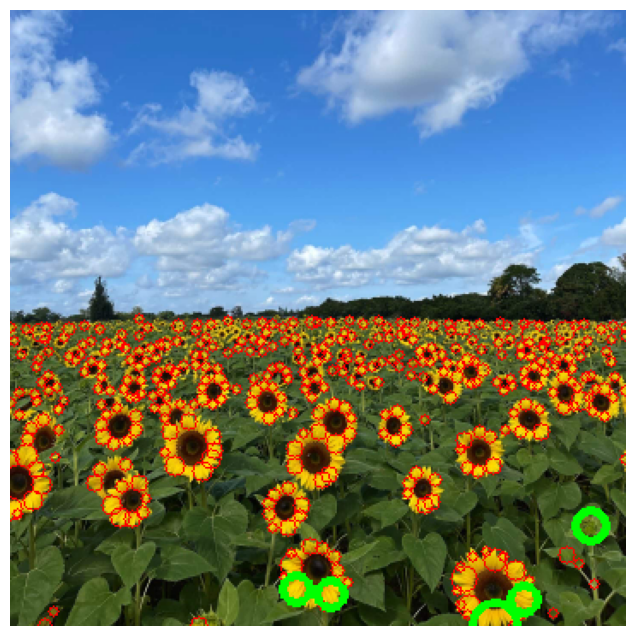

sigma range: 2.0 to 22.0 (20 levels)
#       x     y   sigma   radius
1     283   359    9.09    12.86
2     339   301    6.23     8.81
3     187   341    5.49     7.76
4     167   338    5.49     7.76
5     300   344    5.49     7.76


In [2]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt, glob
from scipy.ndimage import maximum_filter

# Load image
path = glob.glob('a2images/**/the_berry_farms_sunflower_field.jpeg', recursive=True)[0]
im = cv.imread(path, cv.IMREAD_REDUCED_COLOR_4)
rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)

# Yellowness channel: petals bright, sky/leaves dark
f = rgb.astype(np.float32) / 255
f = np.clip((f[..., 0] + f[..., 1]) / 2 - f[..., 2], 0, 1)

# Scale-normalised LoG stack
sigmas = np.geomspace(2, 22, 20)
stack = np.stack([-(s**2) * cv.Laplacian(cv.GaussianBlur(f, (0, 0), s), cv.CV_32F)
                  for s in sigmas])

# 3D local maxima (x, y, sigma)
thr = 0.08
mx = maximum_filter(stack, size=3, mode='nearest')
si, ys, xs = np.where((stack == mx) & (stack > thr))
blobs = sorted([(x, y, sigmas[i], np.sqrt(2) * sigmas[i], stack[i, y, x])
                for i, y, x in zip(si, ys, xs)], key=lambda b: -b[4])

# Remove overlapping circles (keep strongest)
kept = []
for b in blobs:
    if all(np.hypot(b[0]-k[0], b[1]-k[1]) >= 0.7 * max(b[3], k[3]) for k in kept):
        kept.append(b)

# Draw: all in red, 5 largest in green
out = rgb.copy()
largest = sorted(kept, key=lambda b: -b[3])[:5]
for x, y, s, r, _ in kept:
    cv.circle(out, (int(x), int(y)), int(round(r)), (255, 0, 0), 1)
for x, y, s, r, _ in largest:
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 255, 0), 3)

plt.figure(figsize=(8, 8)); plt.imshow(out); plt.axis('off'); plt.show()

# Report
print(f"sigma range: {sigmas[0]:.1f} to {sigmas[-1]:.1f} ({len(sigmas)} levels)")
print(f"{'#':<3}{'x':>6}{'y':>6}{'sigma':>8}{'radius':>9}")
for n, (x, y, s, r, _) in enumerate(largest, 1):
    print(f"{n:<3}{x:>6}{y:>6}{s:>8.2f}{r:>9.2f}")

QUESTION 2

Line sample model : a,b=[-0.697 -0.717], d=-1.242
Line refit (TLS)  : a,b=[-0.718 -0.696], d=-1.521, inliers=58
Circle sample model: center=[2.096 3.016], r=9.948
Circle refit      : center=(1.890,3.080), r=9.944, inliers=41
Ground truth      : center=(2,3), r=10; line y=-x+2


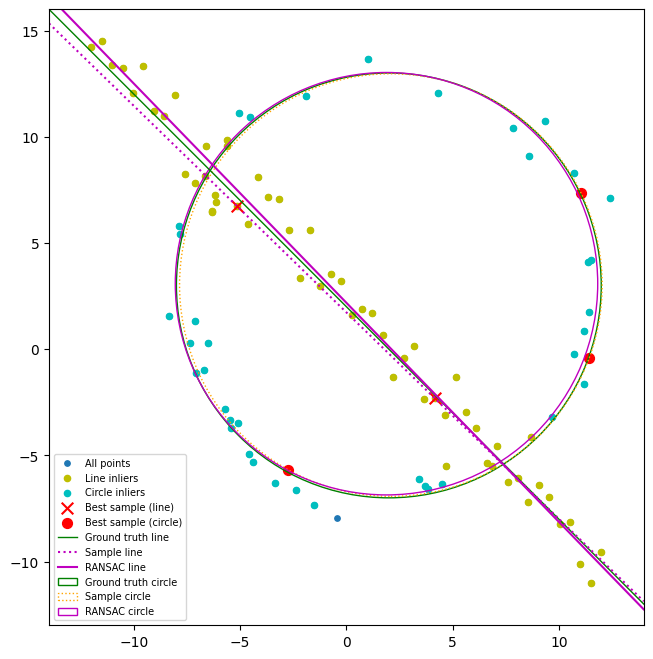

In [3]:
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

# ---- Generate data (Listing 1) ----
N = 100; half_n = N // 2
r, x0_gt, y0_gt = 10, 2, 3
t_ = np.random.uniform(0, 2*np.pi, half_n)
n_ = (r/16) * np.random.randn(half_n)
X_circ = np.c_[x0_gt + (r+n_)*np.cos(t_), y0_gt + (r+n_)*np.sin(t_)]
m, b = -1, 2
xl = np.linspace(-12, 12, half_n)
X_line = np.c_[xl, m*xl + b + np.random.randn(half_n)]
X = np.vstack((X_circ, X_line))

# ---- Helpers ----
def line_from_pts(p, q):                 # unit normal (a,b) and d
    dx, dy = q - p
    L = np.hypot(dx, dy)
    if L < 1e-9: return None
    n = np.array([-dy, dx]) / L          # ||n|| = 1
    return n, n @ p

def tls_line(P):                         # total least squares refit
    mu = P.mean(0); U = P - mu
    n = np.linalg.eigh(U.T @ U)[1][:, 0] # smallest eigenvalue
    return n, n @ mu

def circle_from_pts(p1, p2, p3):         # circle through 3 points
    A = 2*np.array([p2-p1, p3-p1])
    c = np.array([p2@p2 - p1@p1, p3@p3 - p1@p1])
    if abs(np.linalg.det(A)) < 1e-9: return None
    ctr = np.linalg.solve(A, c)
    return ctr, np.linalg.norm(p1 - ctr)

# ---- (a) RANSAC line ----
t_line, d_line, iters = 1.96*1.0, 35, 200   # thresh = 1.96*sigma
best_n, best = 0, None
for _ in range(iters):
    idx = np.random.choice(len(X), 2, replace=False)
    mdl = line_from_pts(X[idx[0]], X[idx[1]])
    if mdl is None: continue
    inl = np.abs(X @ mdl[0] - mdl[1]) < t_line
    if inl.sum() >= d_line and inl.sum() > best_n:
        best_n, best = inl.sum(), (idx, mdl, inl)
l_idx, l_sample, l_inl = best
a_b, d_fit = tls_line(X[l_inl])          # refit on inliers
print(f"Line sample model : a,b={l_sample[0].round(3)}, d={l_sample[1]:.3f}")
print(f"Line refit (TLS)  : a,b={a_b.round(3)}, d={d_fit:.3f}, inliers={l_inl.sum()}")

# ---- (b) RANSAC circle on remnant ----
R = X[~l_inl]
t_circ, d_circ = 1.96*(r/16), 25         # thresh = 1.96*sigma
best_n, bestc = 0, None
for _ in range(iters):
    idx = np.random.choice(len(R), 3, replace=False)
    mdl = circle_from_pts(*R[idx])
    if mdl is None: continue
    inl = np.abs(np.linalg.norm(R - mdl[0], axis=1) - mdl[1]) < t_circ
    if inl.sum() >= d_circ and inl.sum() > best_n:
        best_n, bestc = inl.sum(), (idx, mdl, inl)
c_idx, c_sample, c_inl = bestc

# Refit circle on inliers with minimize
P = R[c_inl]
cost = lambda p: np.sum((np.linalg.norm(P - p[:2], axis=1) - p[2])**2)
res = minimize(cost, [*c_sample[0], c_sample[1]])
cx, cy, cr = res.x
print(f"Circle sample model: center={c_sample[0].round(3)}, r={c_sample[1]:.3f}")
print(f"Circle refit      : center=({cx:.3f},{cy:.3f}), r={cr:.3f}, inliers={c_inl.sum()}")
print(f"Ground truth      : center=({x0_gt},{y0_gt}), r={r}; line y=-x+2")

# ---- (c) Plot ----
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, c='tab:blue', s=15, label='All points')
ax.scatter(*X[l_inl].T, c='y', s=20, label='Line inliers')
ax.scatter(*P.T, c='c', s=20, label='Circle inliers')
ax.scatter(*X[l_idx].T, c='r', marker='x', s=70, label='Best sample (line)')
ax.scatter(*R[c_idx].T, c='r', s=50, label='Best sample (circle)')

xs = np.array([-14, 14])
def line_y(n, d): return (d - n[0]*xs) / n[1]
ax.plot(xs, m*xs + b, 'g-', lw=1, label='Ground truth line')
ax.plot(xs, line_y(*l_sample), 'm:', label='Sample line')
ax.plot(xs, line_y(a_b, d_fit), 'm-', label='RANSAC line')
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, fill=False, color='g', label='Ground truth circle'))
ax.add_patch(plt.Circle(c_sample[0], c_sample[1], fill=False, color='orange', ls=':', label='Sample circle'))
ax.add_patch(plt.Circle((cx, cy), cr, fill=False, color='m', label='RANSAC circle'))
ax.set_xlim(-14, 14); ax.set_ylim(-13, 16); ax.set_aspect('equal'); ax.legend(fontsize=7)
plt.show()

QUESTION 3

Pair 1: points = [[148.0, 199.0], [507.0, 277.0], [509.0, 504.0], [133.0, 506.0]]
H =
[[ 2.80e-01 -2.20e-02  1.48e+02]
 [ 9.10e-02  2.95e-01  1.99e+02]
 [ 0.00e+00 -0.00e+00  1.00e+00]]



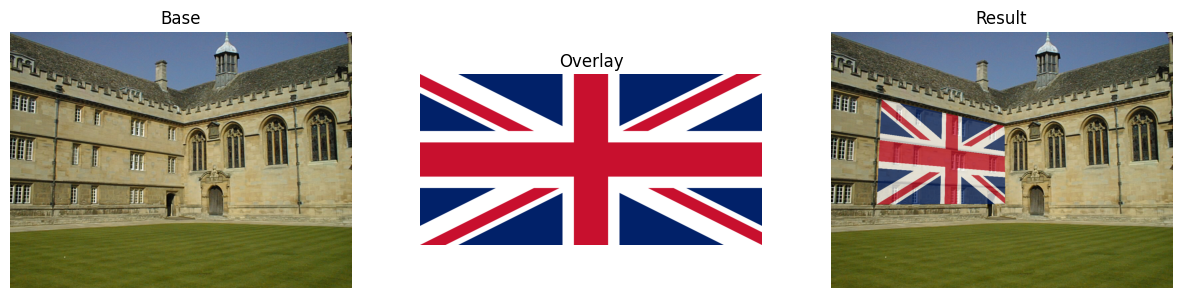

Pair 2: points = [[400.0, 237.0], [490.0, 241.0], [494.0, 317.0], [402.0, 321.0]]
H =
[[ 3.00e-01 -2.00e-02  4.00e+02]
 [ 6.20e-02  1.77e-01  2.37e+02]
 [ 0.00e+00 -0.00e+00  1.00e+00]]



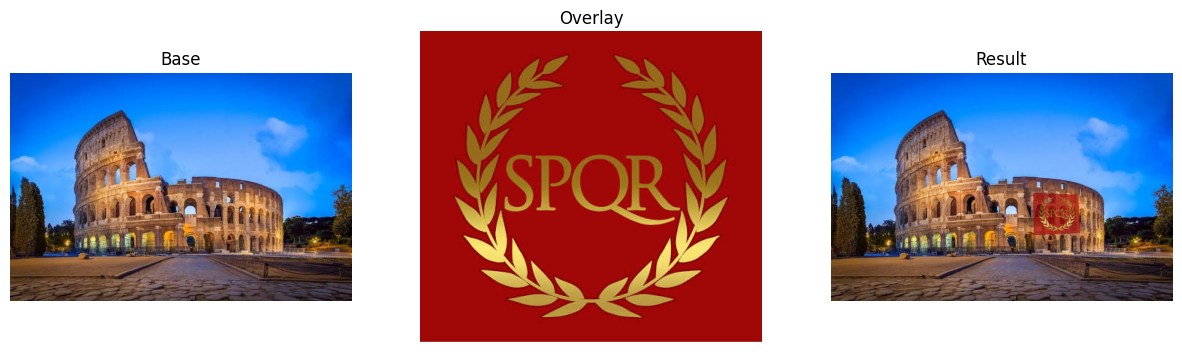

Pair 3: points = [[184.0, 253.0], [332.0, 241.0], [342.0, 337.0], [192.0, 337.0]]
H =
[[ 2.80e-02  3.00e-03  1.84e+02]
 [-1.10e-02  3.80e-02  2.53e+02]
 [-0.00e+00 -0.00e+00  1.00e+00]]



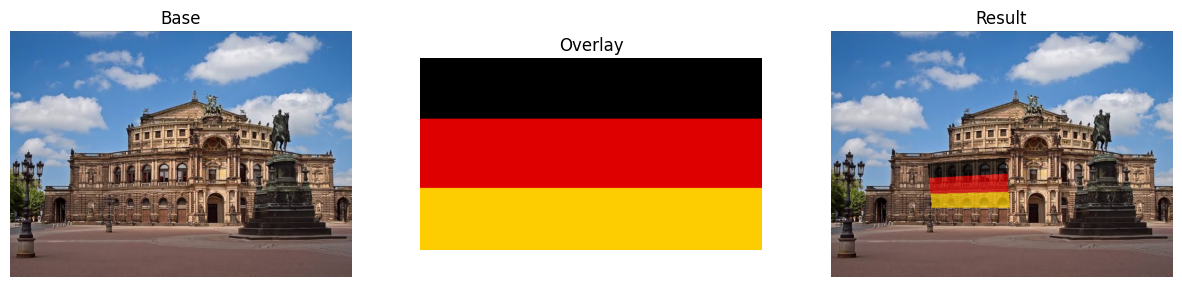

In [8]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt

# (base image, overlay image) - edit file names
pairs = [('a2images/wadham.jpg',      'a2images/UK flag.png'),
         ('a2images/rome colosium.jfif',   'a2images/rome flag.jfif'),
         ('a2images/German opera house.jfif',  'a2images/flag of germany.jpg')]
alpha = 0.7   # overlay strength

def load(p, w=1000):                       # load, shrink if large
    im = cv.imread(p); s = w / im.shape[1]
    return cv.resize(im, None, fx=s, fy=s) if s < 1 else im

def click4(im):                            # TL, TR, BR, BL
    pts, show = [], im.copy()
    def cb(e, x, y, f, p):
        if e == cv.EVENT_LBUTTONDOWN and len(pts) < 4:
            pts.append((x, y)); cv.circle(show, (x, y), 5, (0, 0, 255), -1)
    cv.namedWindow('click 4 points'); cv.setMouseCallback('click 4 points', cb)
    while len(pts) < 4:
        cv.imshow('click 4 points', show)
        if cv.waitKey(20) == 27: break
    cv.destroyAllWindows()
    return np.float32(pts)

def superimpose(base, flag, dst):
    h, w = flag.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    H, _ = cv.findHomography(src, dst)                  # flag -> plane
    size = (base.shape[1], base.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.ones((h, w), np.float32), H, size)[..., None]
    out = base * (1 - alpha * mask) + warped * alpha * mask
    return out.astype(np.uint8), H

for i, (bp, fp) in enumerate(pairs, 1):
    base, flag = load(bp), cv.imread(fp)
    dst = click4(base)
    out, H = superimpose(base, flag, dst)
    print(f"Pair {i}: points = {dst.tolist()}\nH =\n{np.round(H, 3)}\n")
    cv.imwrite(f'q3_result_{i}.png', out)
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    for a, im, t in zip(ax, [base, flag, out], ['Base', 'Overlay', 'Result']):
        a.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB)); a.set_title(t); a.axis('off')
    plt.show()

QUESTION 4

AAAA1: keypoints=2414, good matches=51, inliers=18


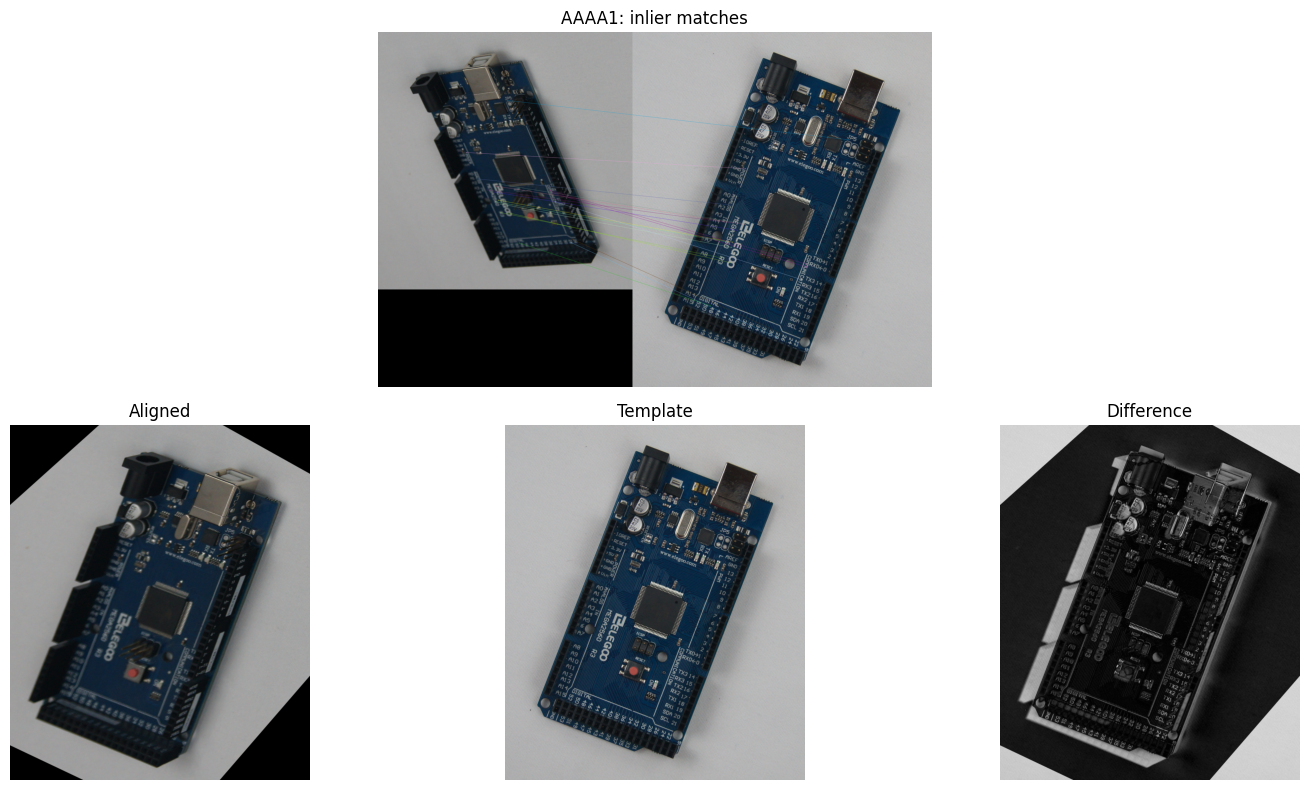

ADAD1: keypoints=8486, good matches=369, inliers=194


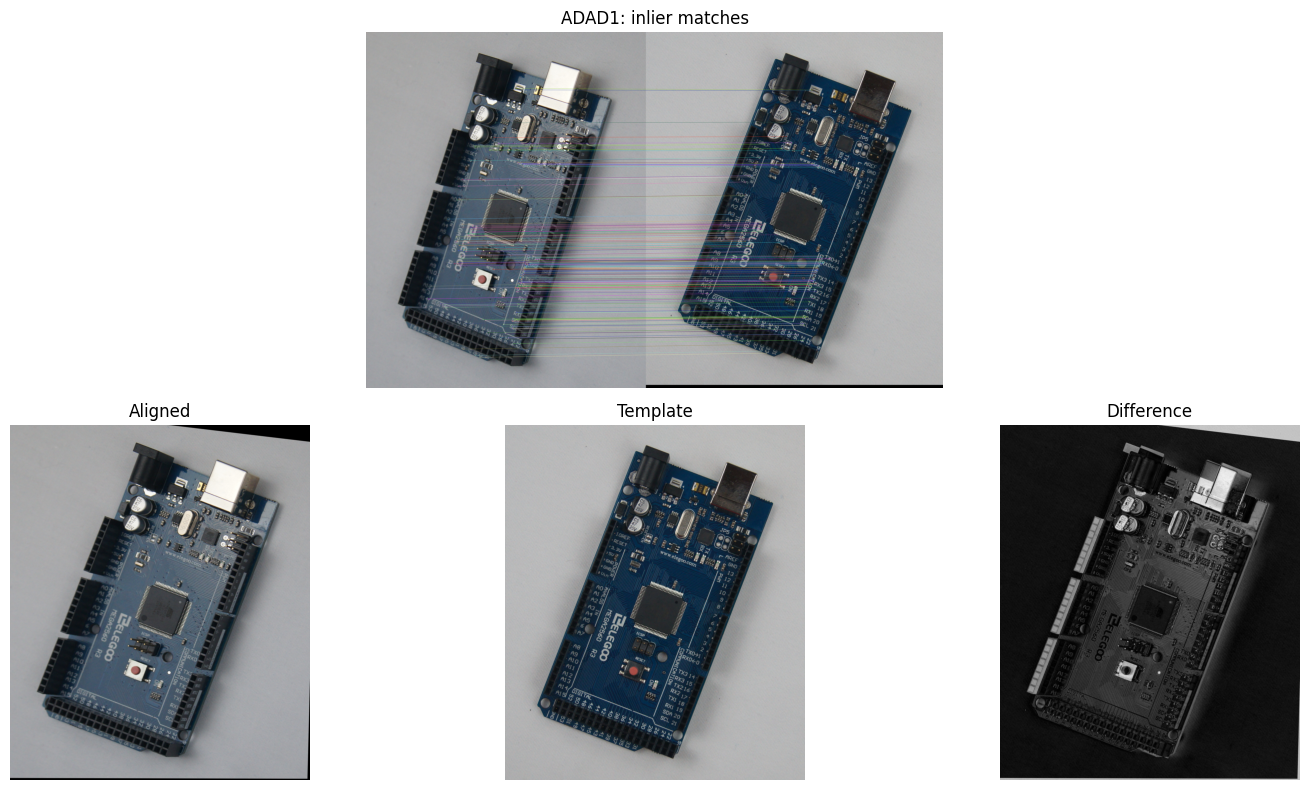

AECC2: keypoints=12315, good matches=4322, inliers=3847


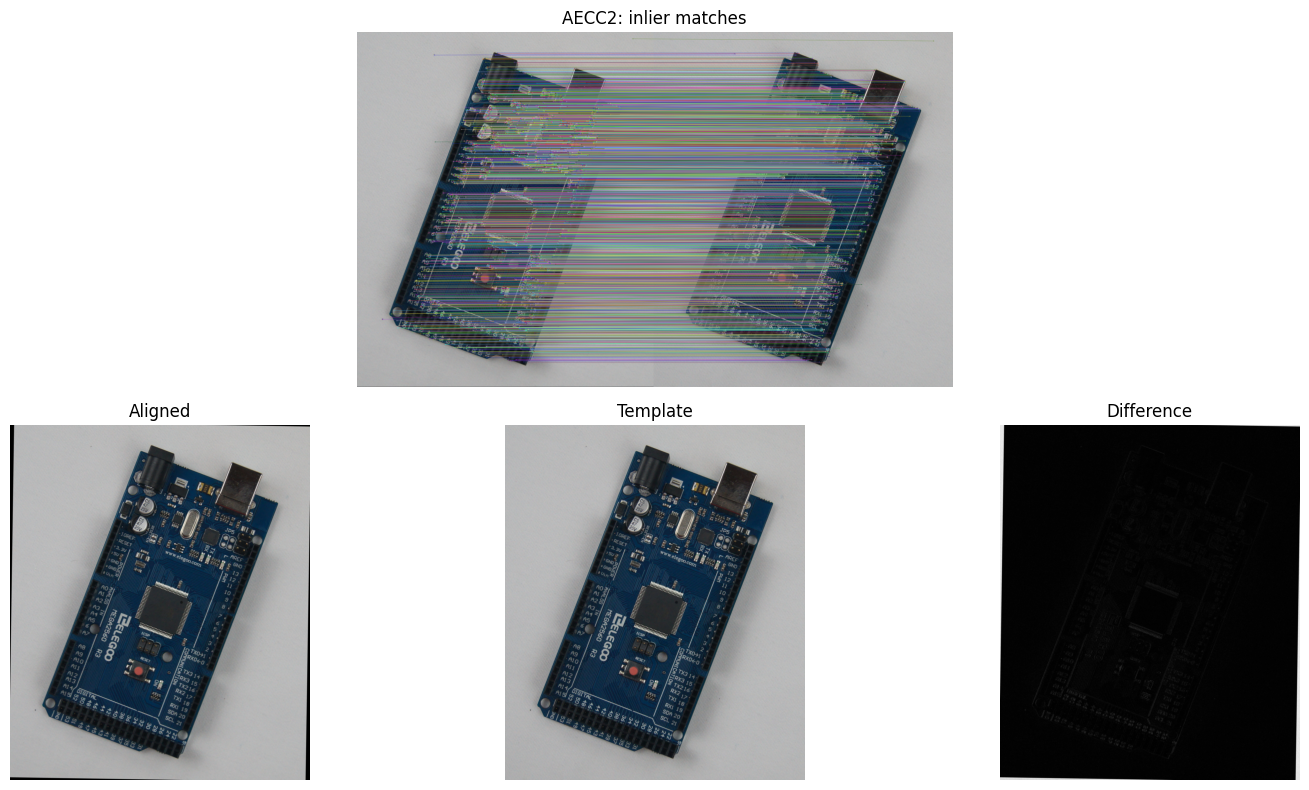

AECC3: keypoints=15198, good matches=5629, inliers=5006


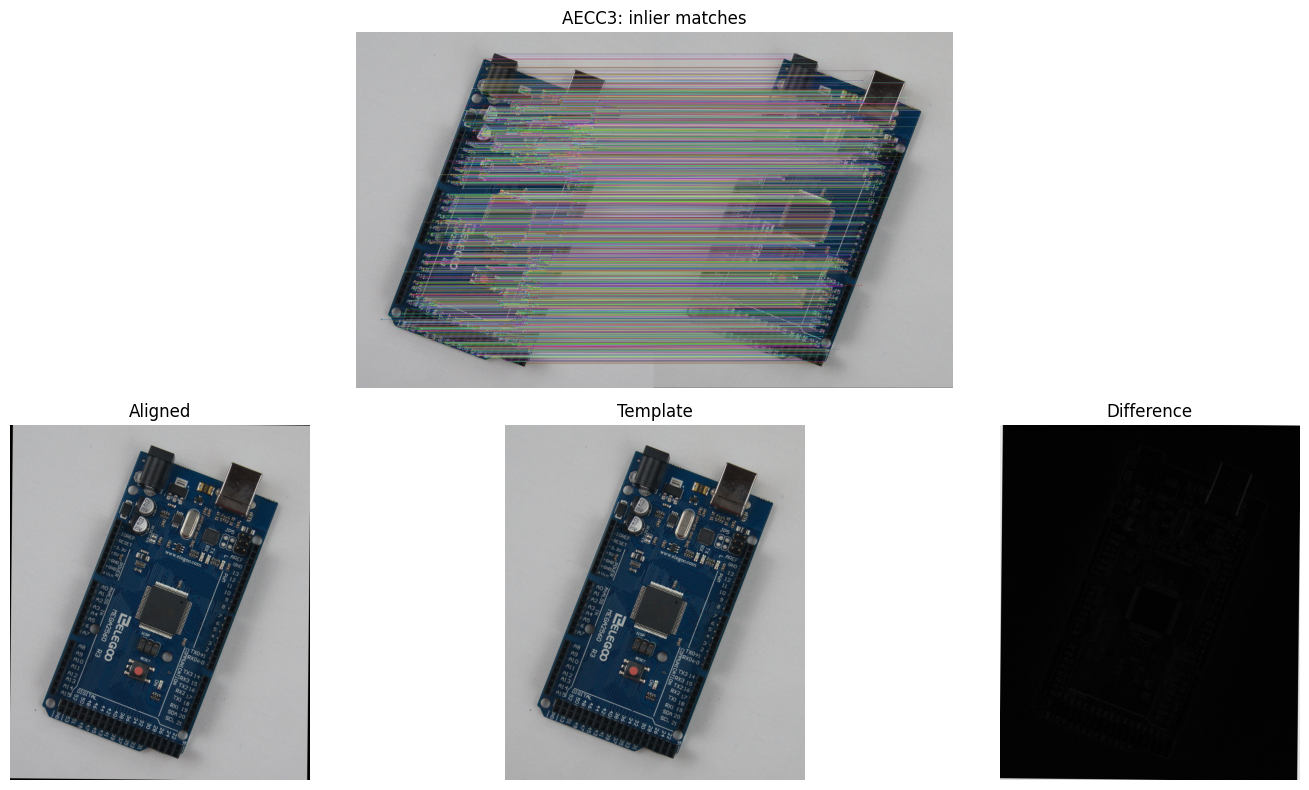

AECC4: keypoints=11610, good matches=3830, inliers=3402


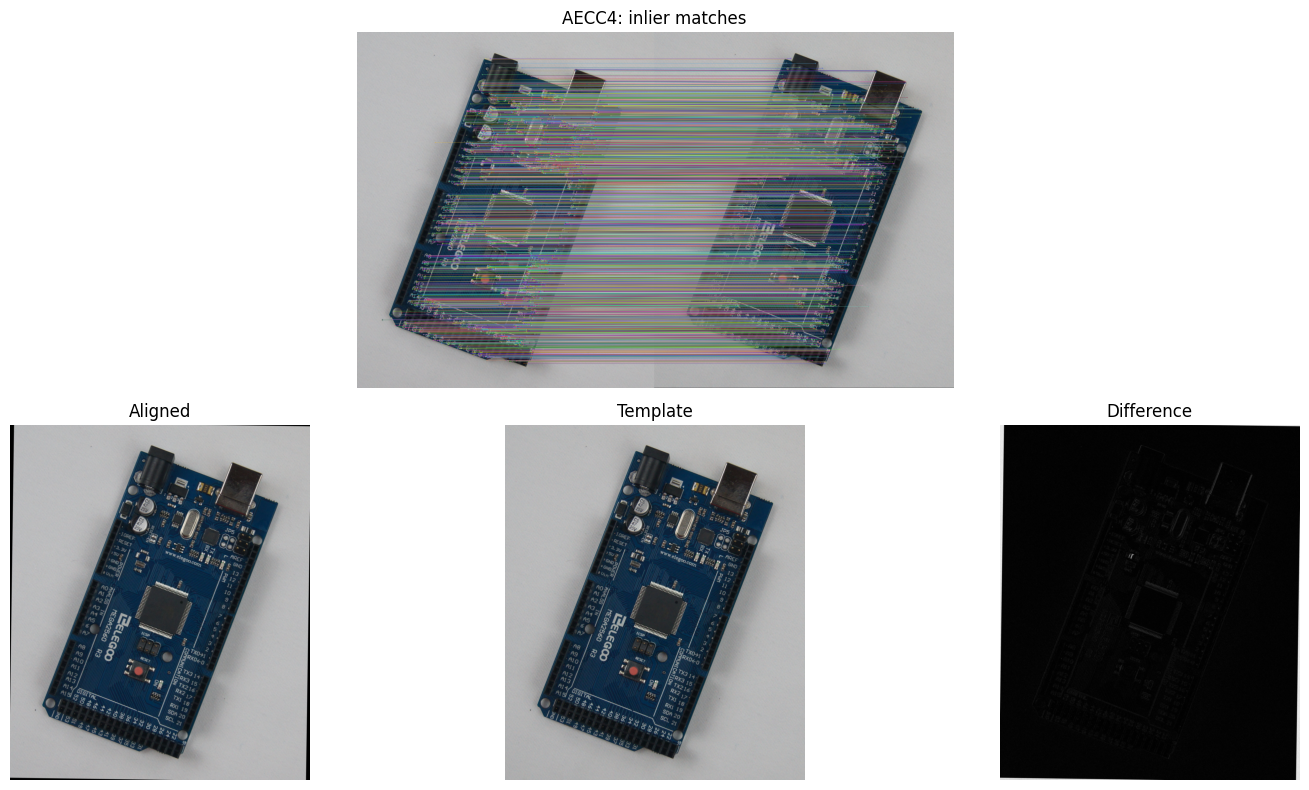

In [9]:
import cv2 as cv, numpy as np, matplotlib.pyplot as plt

folder = 'a2images/pcbs/'
names = ['AAAA1', 'ADAD1', 'AECC2', 'AECC3', 'AECC4']
tmpl = cv.imread(folder + 'AECC1.jpg')
tg = cv.cvtColor(tmpl, cv.COLOR_BGR2GRAY)
h, w = tg.shape

sift = cv.SIFT_create()                       # (a) SIFT
kp1, des1 = sift.detectAndCompute(tg, None)
bf = cv.BFMatcher()

for n in names:
    img = cv.imread(folder + n + '.jpg')
    g = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    kp2, des2 = sift.detectAndCompute(g, None)

    # (b) match + ratio test, then RANSAC homography (image -> template)
    raw = bf.knnMatch(des2, des1, k=2)
    good = [a for a, b in raw if a.distance < 0.75 * b.distance]
    src = np.float32([kp2[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    inl = mask.ravel().astype(bool)
    print(f"{n}: keypoints={len(kp2)}, good matches={len(good)}, inliers={inl.sum()}")

    # (c) warp to template and take difference
    warped = cv.warpPerspective(img, H, (w, h))
    diff = cv.absdiff(cv.cvtColor(warped, cv.COLOR_BGR2GRAY), tg)

    # Show: matches (RANSAC inliers only), aligned image, difference
    vis = cv.drawMatches(img, kp2, tmpl, kp1,
                         [m for m, k in zip(good, inl) if k], None,
                         flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    fig = plt.figure(figsize=(15, 8))
    ax = fig.add_subplot(2, 1, 1)
    ax.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB)); ax.set_title(f'{n}: inlier matches'); ax.axis('off')
    for i, (im, t, cm) in enumerate([(cv.cvtColor(warped, cv.COLOR_BGR2RGB), 'Aligned', None),
                                      (cv.cvtColor(tmpl, cv.COLOR_BGR2RGB), 'Template', None),
                                      (diff, 'Difference', 'gray')]):
        a = fig.add_subplot(2, 3, 4 + i)
        a.imshow(im, cmap=cm); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()
    cv.imwrite(f'q4_diff_{n}.png', diff)
    